In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv(r"C:\Users\surfce\Downloads\Mall_Customers.csv")
data.columns = data.columns.str.strip()

In [3]:
data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
data.tail()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [6]:
data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [7]:
data.shape

(200, 5)

In [8]:
data.dtypes

CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

In [9]:
data.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [10]:
data.duplicated().sum()

np.int64(0)

In [11]:
numerical = data.select_dtypes(include=np.number).columns
categorical = data.select_dtypes(exclude=np.number).columns

print("Numerical Variables:", list(numerical))
print("Categorical Variables:", list(categorical))

Numerical Variables: ['CustomerID', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Categorical Variables: ['Gender']


In [12]:
for col in numerical:
    data[col] = data[col].fillna(data[col].median())

for col in categorical:
    if not data[col].mode().empty:
        data[col] = data[col].fillna(data[col].mode()[0])

data.drop_duplicates(inplace=True)

data.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

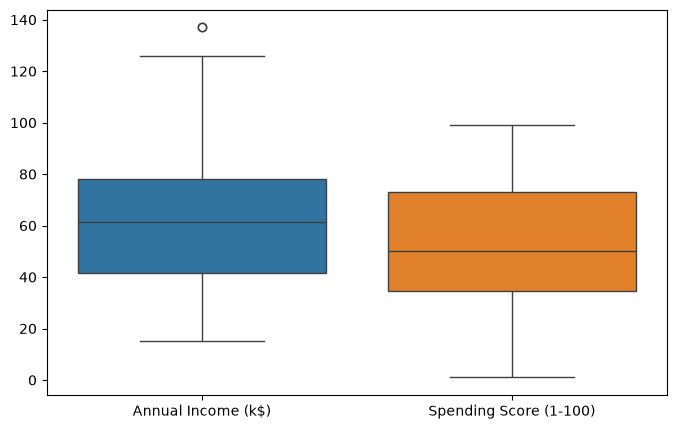

In [13]:
feature_cols = ['Annual Income (k$)', 'Spending Score (1-100)']

plt.figure(figsize=(8, 5))
sns.boxplot(data=data[feature_cols])
plt.show()

In [14]:
for col in feature_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    data[col] = data[col].clip(lower, upper)

In [15]:
x = data[feature_cols]
x.head()

,Annual Income (k$),Spending Score (1-100)
0,15.0,39
1,15.0,81
2,16.0,6
3,16.0,77
4,17.0,40


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

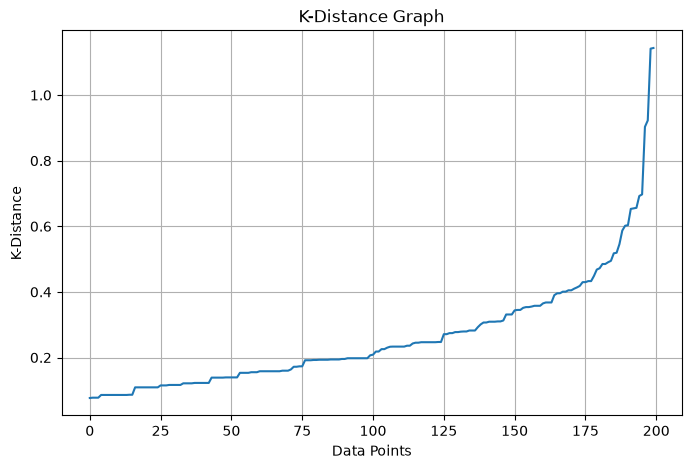

In [17]:
from sklearn.neighbors import NearestNeighbors

min_samples = 2 * x_scaled.shape[1]

neighbors = NearestNeighbors(n_neighbors=min_samples + 1)
neighbors.fit(x_scaled)

distances, indices = neighbors.kneighbors(x_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel("Data Points")
plt.ylabel("K-Distance")
plt.title("K-Distance Graph")
plt.grid()
plt.show()

In [18]:
line = np.linspace(k_distances[0], k_distances[-1], len(k_distances))
elbow_index = np.argmax(k_distances - line)
eps = float(k_distances[elbow_index])

print("Suggested Epsilon:", eps)
print("MinPts:", min_samples)

Suggested Epsilon: 1.1414638921993763
MinPts: 4


In [19]:
from sklearn.cluster import DBSCAN

model = DBSCAN(eps=eps, min_samples=min_samples)
labels = model.fit_predict(x_scaled)

data['Cluster'] = labels

data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15.0,39,0
1,2,Male,21,15.0,81,0
2,3,Female,20,16.0,6,0
3,4,Female,23,16.0,77,0
4,5,Female,31,17.0,40,0


In [20]:
print("Cluster Labels:")
print(data['Cluster'].value_counts().sort_index())

Cluster Labels:
Cluster
0    200
Name: count, dtype: int64


In [21]:
n_clusters = len(set(labels) - {-1})
n_noise = int(np.sum(labels == -1))

print("Number of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

Number of Clusters: 1
Number of Noise Points: 0


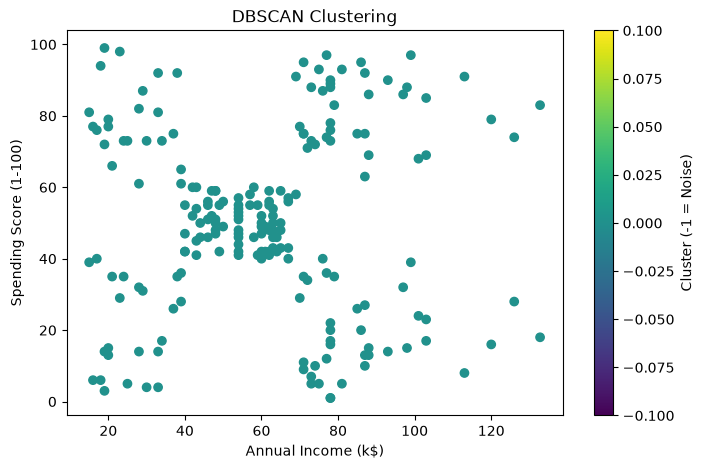

In [22]:
plt.figure(figsize=(8, 5))
plt.scatter(data[feature_cols[0]], data[feature_cols[1]], c=labels, cmap='viridis')
plt.xlabel(feature_cols[0])
plt.ylabel(feature_cols[1])
plt.title("DBSCAN Clustering")
plt.colorbar(label="Cluster (-1 = Noise)")
plt.show()

In [23]:
cluster_analysis = data[data['Cluster'] != -1].groupby('Cluster')[feature_cols].mean()

print("Cluster Analysis:")
print(cluster_analysis)

Cluster Analysis:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                   60.5175                    50.2


In [24]:
from sklearn.metrics import silhouette_score

valid_points = labels != -1
valid_labels = labels[valid_points]

if len(set(valid_labels)) > 1 and len(valid_labels) > len(set(valid_labels)):
    score = silhouette_score(x_scaled[valid_points], valid_labels)
    print("Silhouette Score:", score)
else:
    score = None
    print("Silhouette Score is not applicable because fewer than two non-noise clusters were found.")

Silhouette Score is not applicable because fewer than two non-noise clusters were found.


In [25]:
print("Number of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)
print("Epsilon:", eps)
print("MinPts:", min_samples)

if score is not None:
    print("Silhouette Score:", round(score, 4))

print("DBSCAN Clustering Completed Successfully!")

Number of Clusters: 1
Number of Noise Points: 0
Epsilon: 1.1414638921993763
MinPts: 4
DBSCAN Clustering Completed Successfully!
